# xAI
1. TF-IDF baseline: n-grams with the largest per-class coefficients (same data, sample and config as the baseline).
2. Ensemble: which models the stacker relies on (standardized coefficients, refit on the full val fold, same as postproc).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

SEED = 42
LABELS = ['human', 'ai', 'fusion']
COLORS = {'human': '#2a78d6', 'ai': '#d64545', 'fusion': '#8a5cc2'}
SUB_N = 50_000
FULL_N = 100_000
TOP = 20
INPUT = Path('/kaggle/input')
FIG = Path('figures')
FIG.mkdir(exist_ok=True)

train = pd.read_parquet(next(INPUT.rglob('train_clean.parquet')), columns=['id', 'text', 'lang', 'domain', 'label', 'fold'])

def strat_sample(df, n):
    return df.groupby(['label', 'lang', 'domain'], group_keys=False).sample(frac=min(n / len(df), 1), random_state=SEED)

tr = train[train.fold == 'train']
sub_tr = strat_sample(tr, SUB_N)
tr = strat_sample(tr, FULL_N)
v = train[train.fold == 'val'].set_index('id')
del train
len(tr), len(sub_tr), len(v)

(99998, 50000, 54537)

## 1. TF-IDF baseline: top n-grams per class

In [2]:
VECS = {
    'word': TfidfVectorizer(ngram_range=(1, 2), token_pattern=r'(?u)\w+|[^\w\s]', min_df=3, max_features=200_000, sublinear_tf=True, dtype=np.float32),
    'char': TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=200_000, sublinear_tf=True, dtype=np.float32),
}

def transform(vec, texts, chunk=10_000):
    return sp.vstack([vec.transform(texts.iloc[i:i + chunk]) for i in range(0, len(texts), chunk)]).tocsr()

for vec in VECS.values():
    vec.fit(sub_tr.text)
X = sp.hstack([transform(vec, tr.text) for vec in VECS.values()]).tocsr()
lr = LogisticRegression(C=3, class_weight='balanced', max_iter=2000).fit(X, tr.label)
del X

coef = pd.DataFrame(lr.coef_.T, columns=lr.classes_, index=pd.MultiIndex.from_tuples(
    [(k, f) for k, vec in VECS.items() for f in vec.get_feature_names_out()], names=['kind', 'ngram']))
top = {(k, c): coef.xs(k)[c].nlargest(TOP) for k in VECS for c in LABELS}
pd.DataFrame({f'{c} ({k})': s.index.str.replace(' ', '·') for (k, c), s in top.items()})

,human (word),ai (word),fusion (word),human (char),ai (char),fusion (char)
0,dank·.,"""",.·…,.'·,’s·,·'·
1,.·vielen,!,.·this,.’·,·–·,·’·
2,dank,?,me·know,".""·",t?·,"·""·"
3,vielen·dank,’,…,dank.,e!·,·...
4,of·the,’·s,.·.,dank,s!·,·..
5,in·conclusion,—,.·',·dank,it’,·u.·
6,.·danke,.·“,know·if,ank.,·it’,·…·
7,danke,",·i",let·me,ank.·,t’s,·s.·
8,.·herzlichen,*,missing·part,u.s,t’s·,·s.
9,?·i,it·’,.·and,u.s.,it’s,·.·


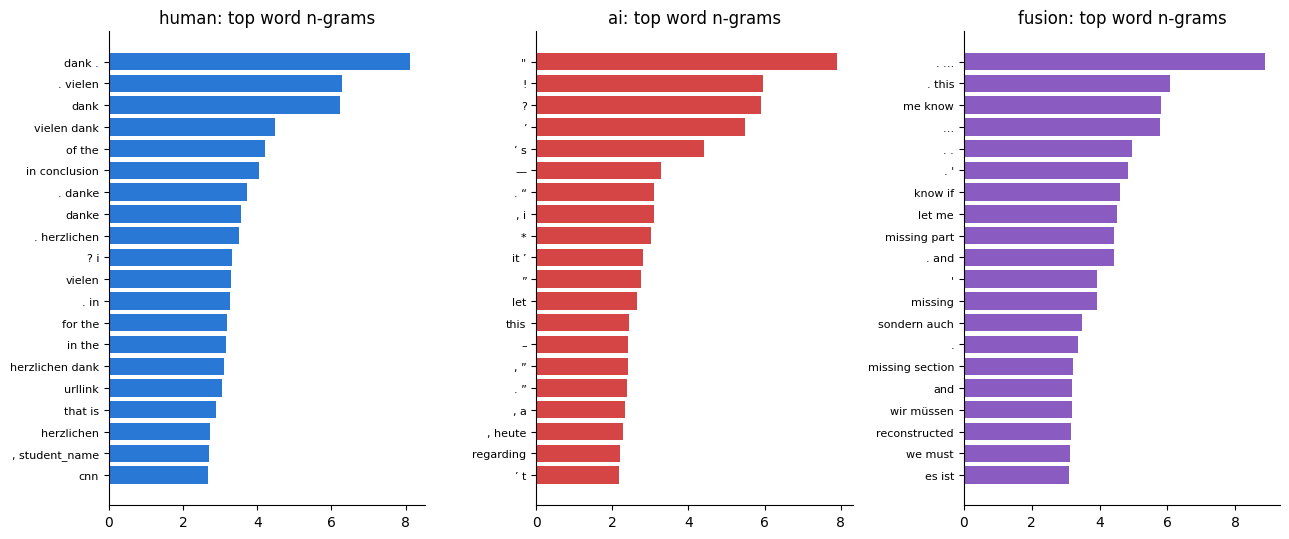

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 5.5))
for a, c in zip(ax, LABELS):
    s = top['word', c][::-1]
    a.barh(s.index, s.values, color=COLORS[c])
    a.set_title(f'{c}: top word n-grams')
    a.spines[['top', 'right']].set_visible(False)
    a.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig(FIG / 'xai_tfidf_top.png', bbox_inches='tight', dpi=150)
plt.show()

## 2. Ensemble: stacker reliance on each model
Inputs are correlated and models with more columns get larger sums, so this shows reliance, not contribution; `all - X` ablations in postproc are the complementary view.

In [4]:
sample_sub = pd.read_csv(next(INPUT.rglob('sample_submission.csv')))
models = {}
for f in sorted(INPUT.rglob('val_*.csv')):
    if f.with_name('test_' + f.name[4:]).exists():
        models[f.stem[4:]] = pd.read_csv(f, index_col='id').loc[v.index]
S = pd.concat([m.add_prefix(f'{n}:') for n, m in models.items()], axis=1)
stack = LogisticRegression(C=1, max_iter=2000).fit(StandardScaler().fit_transform(S), v.label)
W = pd.DataFrame(stack.coef_.T, index=S.columns, columns=stack.classes_)[LABELS]
W.round(3)

,human,ai,fusion
scores_baseline:ai,-0.829,0.751,0.077
scores_baseline:fusion,-0.429,-0.129,0.557
scores_baseline:human,0.978,-0.730,-0.248
logits_xlmr_full:human,1.373,-0.783,-0.590
logits_xlmr_full:ai,-0.191,1.127,-0.936
logits_xlmr_full:fusion,-0.565,-0.934,1.498
logits_xlmr_headtail:human,-0.042,0.260,-0.218
logits_xlmr_headtail:ai,0.124,-0.160,0.037
logits_xlmr_headtail:fusion,0.316,-0.010,-0.305
logits_mdeberta_headtail:human,-0.052,-0.176,0.228


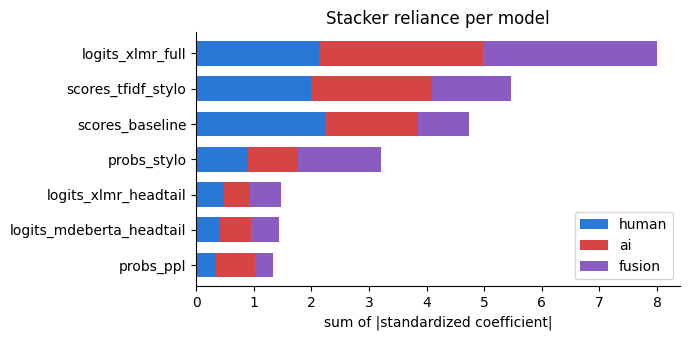

,human,ai,fusion,n_cols
probs_ppl,0.35,0.67,0.32,3
logits_mdeberta_headtail,0.42,0.53,0.48,3
logits_xlmr_headtail,0.48,0.43,0.56,3
probs_stylo,0.90,0.86,1.45,3
scores_baseline,2.24,1.61,0.88,3
scores_tfidf_stylo,2.00,2.10,1.37,3
logits_xlmr_full,2.13,2.84,3.02,3


In [5]:
reliance = W.abs().groupby(W.index.str.split(':').str[0]).sum()
reliance = reliance.loc[reliance.sum(1).sort_values().index]
reliance.plot.barh(stacked=True, color=[COLORS[c] for c in LABELS], figsize=(7, 3.5), width=.7)
plt.xlabel('sum of |standardized coefficient|')
plt.title('Stacker reliance per model')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / 'xai_stacker.png', bbox_inches='tight', dpi=150)
plt.show()
reliance.assign(n_cols=W.index.str.split(':').str[0].value_counts()).round(2)